# Part C — Chart generation

Generate the multiplayer-comparison charts for Part C: three main charts, the feature risk-ratio heatmap, two platform-type charts, the Japan bridge chart and a follow-up gap chart. Each plotting cell displays its figure and saves a PNG under `part_c/figures/`; evidence tables go to `part_c/tables/`.

**Input:** `data/Video_games_dataset.csv`. Console versions are combined by exact recorded title; sales are in million copies. Part B uses separate title–console records in [analysis.ipynb](analysis.ipynb).

Run all cells with the `.venv` kernel, or from the repo root:
```sh
uv run jupyter nbconvert --to notebook --execute --inplace part_c.ipynb
```

## Setup — data, groups and plotting helpers
`data_prep.load_data()` sums title sales in integer hundredths of a million. Multiplayer is `MaxPlayers >= 2`; retain a title's label only when all recorded versions agree after recoding. Exact-title matching preserves capitalisation differences. Recorded zeros are retained.

Success-or-above thresholds are strict: Global >0.50m, NA >0.20m, EU >0.15m and Japan >0.10m. Global Blockbusters exceed 5m.

The helper below calculates each group's size, success count, proportion and median before plotting.

In [1]:
"""Regenerate the focused multiplayer story's charts and evidence tables."""
from pathlib import Path
import sys
from IPython.display import display
import hashlib
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CWD = Path.cwd()
HERE = CWD if (CWD / "data_prep.py").exists() else CWD / "part_c"
sys.path.insert(0, str(HERE))
from data_prep import load_data, CATEGORY_NAMES, SOURCE
from chart_style import *
for folder in ["figures", "tables"]:
    (HERE / folder).mkdir(exist_ok=True)
raw, titles, genre_cols = load_data()
source_before = hashlib.sha256(SOURCE.read_bytes()).hexdigest()
use_style()
NAMES = ["Single-player-only", "Multiplayer support"]
REGION_TICKS = ["North America\n>0.20m copies", "Europe\n>0.15m copies", "Japan\n>0.10m copies"]
paths = []


def save_table(frame, name):
    path = HERE / "tables" / name
    frame.to_csv(path, index=False)
    paths.append(path)


def save_figure(fig, name):
    path = HERE / "figures" / name
    fig.savefig(path, dpi=170, bbox_inches="tight")
    display(fig)
    plt.close(fig)
    paths.append(path)


def summarise(frame, sample, feature="Multiplayer", region="GlobalSales"):
    rows = []
    for value in [0, 1]:
        d = frame[frame[feature] == value]
        rows.append({"sample": sample, "feature": feature, "value": value, "region": region,
                     "n": len(d), "success_n": int(d[region + "Success"].sum()),
                     "success_pct": 100 * d[region + "Success"].mean(),
                     "median_m": d[region].median(), "mean_m": d[region].mean(),
                     "positive_n": int((d[region] > 0).sum()),
                     "excluded_n": int(frame[feature].isna().sum())})
    return rows


top10 = titles.nlargest(10, "GlobalSales").index
samples = {
    "All titles": titles,
    "Without global Blockbusters": titles[titles.GlobalSales <= 5],
    "Without top 10": titles.drop(top10),
    "1 recorded console": titles[titles.RecordedConsoles == 1],
    "2+ recorded consoles": titles[titles.RecordedConsoles > 1],
}
regions = ["GlobalSales", "NASales", "EUSales", "JapanSales"]
outcomes = pd.DataFrame([row for name, frame in samples.items() for region in regions
                         for row in summarise(frame, name, region=region)])
save_table(outcomes, "mp_story_outcomes.csv")
full = outcomes.query("sample == 'All titles' and region == 'GlobalSales'").set_index("value")

## Chart 1 — Global proportions
Plot each group's global Success-or-above percentage. Label bars with their denominators.

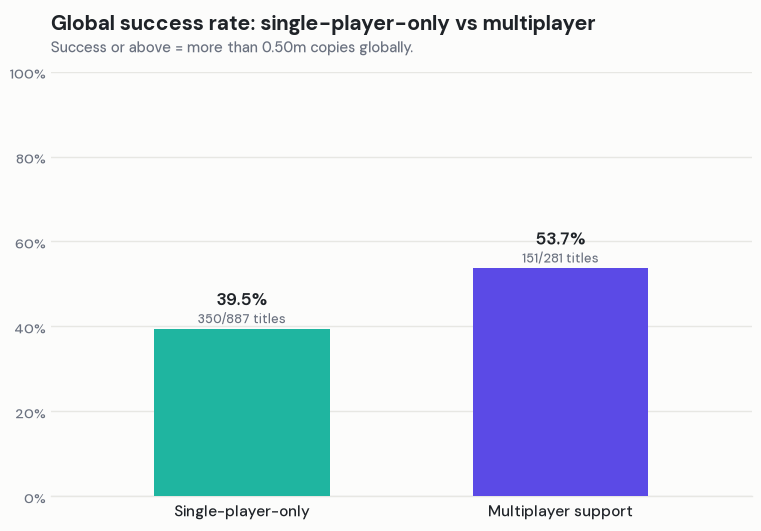

In [2]:
# Main chart 1: global success proportions.
# median panel dropped - success is defined by sales so it was the same result twice
fig, ax = plt.subplots(figsize=(7.5, 5.2), layout="constrained")
for value in [0, 1]:
    row = full.loc[value]
    ax.bar(value, row.success_pct, color=[SP, MP][value], width=.55, zorder=3)
    bar_label(ax, value, row.success_pct, f"{int(row.success_n)}/{int(row.n)} titles")
ax.set_xticks([0, 1], NAMES)
ax.set_xlim(-.6, 1.6)
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
titled(ax, "Global success rate: single-player-only vs multiplayer",
       "Success or above = more than 0.50m copies globally.")
save_figure(fig, "mp_01_global_comparison.png")

## Chart 2 — Excluding global Blockbusters
Use the same proportion calculation on the full sample and the subset with GlobalSales <= 5m. Recalculate group denominators for each subset.

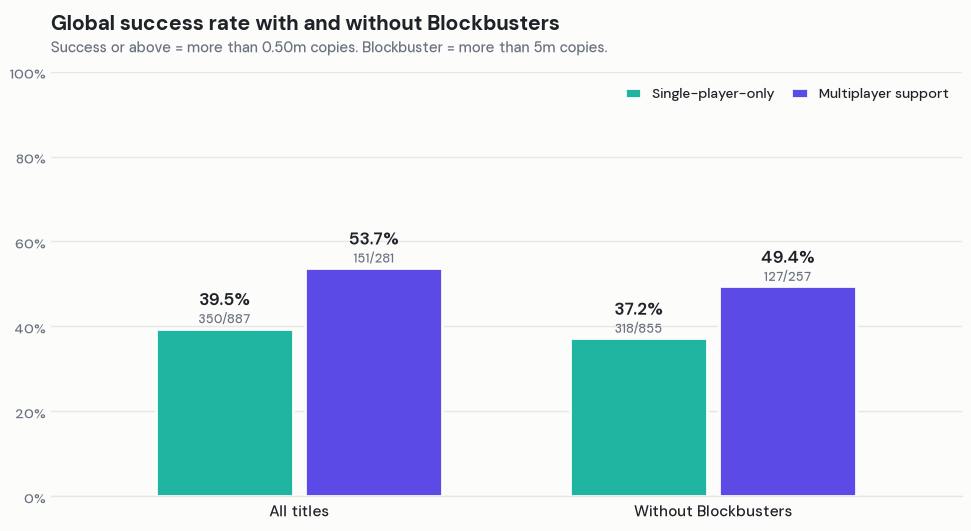

In [3]:
# Main chart 2: sensitivity to a few unusually successful titles.
fig, ax = plt.subplots(figsize=(9.6, 5.2), layout="constrained")
groups = []
for label, sample in [("All titles", "All titles"), ("Without Blockbusters", "Without global Blockbusters")]:
    s = outcomes.query("sample == @sample and region == 'GlobalSales'").set_index("value")
    groups.append((label, [(s.success_pct[v], int(s.success_n[v]), int(s.n[v])) for v in [0, 1]]))
paired_bars(ax, groups, [SP, MP], NAMES)
titled(ax, "Global success rate with and without Blockbusters",
       "Success or above = more than 0.50m copies. Blockbuster = more than 5m copies.")
save_figure(fig, "mp_02_blockbuster_check.png")

## Chart 3 — Regional proportions
Use each region's own threshold. Each pair of bars shares the same within-region comparison; the thresholds differ across regions.

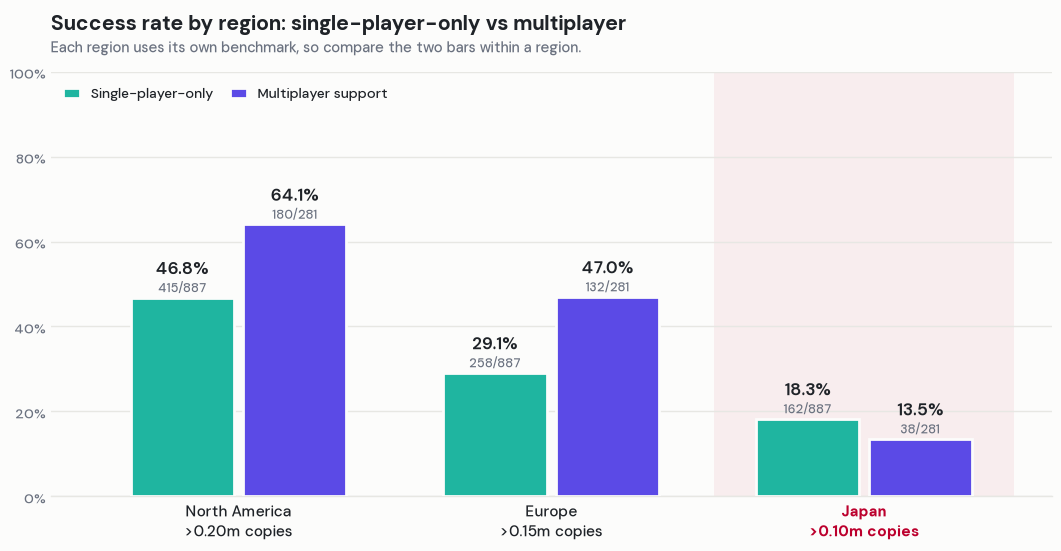

In [4]:
# Main chart 3: within-region comparisons using the brief's own thresholds.
fig, ax = plt.subplots(figsize=(10.5, 5.4), layout="constrained")
groups = []
for label, region in zip(REGION_TICKS, regions[1:]):
    s = outcomes.query("sample == 'All titles' and region == @region").set_index("value")
    groups.append((label, [(s.success_pct[v], int(s.success_n[v]), int(s.n[v])) for v in [0, 1]]))
paired_bars(ax, groups, [SP, MP], NAMES, legend="upper left")
japan_spotlight(ax, 2)
titled(ax, "Success rate by region: single-player-only vs multiplayer",
       "Each region uses its own benchmark, so compare the two bars within a region.")
save_figure(fig, "mp_03_regions.png")

## Feature screen — risk ratios
For each recorded feature, compare the Success-or-above rate of titles with the feature against titles without it, in each market. Risk ratio = rate with ÷ rate without (lecture notes Section 2.2): above 1 is a positive association, below 1 a negative one. Only titles whose versions agree on the feature are used, so group sizes (shown as with vs without) differ by row. Features with fewer than 30 titles in either group, and genres (including the Fighting, Puzzle and Arcade tags), stay in the CSV but are not drawn. Features overlap, so rows are not independent and this is an overview, not a ranking.

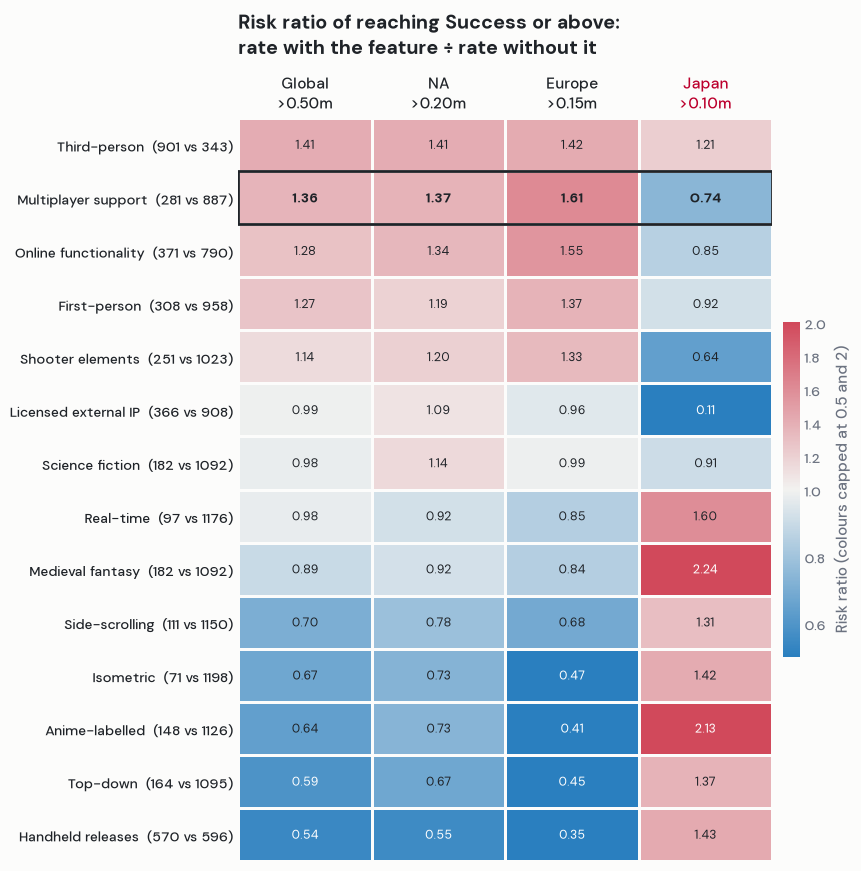

Index(['ThirdPerson', 'Multiplayer', 'Online', 'FirstPerson', 'Shooter',
       'Licensed', 'SciFi', 'RealTime', 'MedievalFantasy', 'SideScrolling',
       'Isometric', 'Anime', 'TopDown', 'Handheld'],
      dtype='str', name='feature')

In [5]:
# Feature screen as risk ratios (lecture notes Section 2.2), not correlations.
from matplotlib.colors import TwoSlopeNorm
from data_prep import BINARY
LABELS = {"Online": "Online functionality", "Multiplayer": "Multiplayer support",
          "Licensed": "Licensed external IP", "Handheld": "Handheld releases",
          "Anime": "Anime-labelled", "MedievalFantasy": "Medieval fantasy", "RealTime": "Real-time",
          "SciFi": "Science fiction", "Shooter": "Shooter elements", "FirstPerson": "First-person",
          "ThirdPerson": "Third-person", "SideScrolling": "Side-scrolling", "TopDown": "Top-down"}


def risk_ratios(frame, sample):
    rows = []
    for f in BINARY + genre_cols:
        d = frame[frame[f].notna()]
        n0, n1 = int((d[f] == 0).sum()), int((d[f] == 1).sum())
        for region in regions:
            k0, k1 = int(d.loc[d[f] == 0, region + "Success"].sum()), int(d.loc[d[f] == 1, region + "Success"].sum())
            rows.append({"sample": sample, "feature": f, "region": region, "n0": n0, "success0": k0, "n1": n1, "success1": k1,
                         "rate0_pct": 100 * k0 / n0 if n0 else np.nan, "rate1_pct": 100 * k1 / n1 if n1 else np.nan,
                         "risk_ratio": (k1 / n1) / (k0 / n0) if n0 and n1 and k0 else np.nan,
                         "shown": min(n0, n1) >= 30})
    return pd.DataFrame(rows)


GENRE_LIKE = genre_cols + ["Fighting", "Puzzle", "Arcade"]


def rr_heatmap(rr, title, name, order=None):
    matrix = rr[rr.shown].pivot(index="feature", columns="region", values="risk_ratio")[regions]
    # same row order as the all-titles chart, so the two can be compared side by side
    matrix = matrix.sort_values("GlobalSales", ascending=False) if order is None else matrix.reindex([f for f in order if f in matrix.index])
    # genres (and genre-like tags) stay in the CSV but are left off the chart to keep it readable
    matrix = matrix.drop([f for f in GENRE_LIKE if f in matrix.index])
    sizes = rr[rr.region == "GlobalSales"].set_index("feature")
    fig, ax = plt.subplots(figsize=(8.5, 1.6 + .5 * len(matrix)), layout="constrained")
    # surface-coloured cell borders give each cell a small gap
    im = ax.pcolormesh(matrix.values, cmap=RR_CMAP, norm=TwoSlopeNorm(vmin=.5, vcenter=1, vmax=2),
                       edgecolors=SURFACE, linewidth=2)
    ax.invert_yaxis()
    ax.grid(False)
    ax.spines["bottom"].set_visible(False)
    ax.xaxis.tick_top()
    ax.set_xticks(np.arange(4) + .5, ["Global\n>0.50m", "NA\n>0.20m", "Europe\n>0.15m", "Japan\n>0.10m"])
    ax.get_xticklabels()[3].set_color(JAPAN_RED)
    ax.set_yticks(np.arange(len(matrix)) + .5,
                  [LABELS.get(f, f) + f"  ({sizes.n1[f]} vs {sizes.n0[f]})" for f in matrix.index])
    ax.tick_params(axis="y", colors=INK)
    for i in range(len(matrix)):
        for j in range(4):
            value = matrix.iloc[i, j]
            bold = matrix.index[i] == "Multiplayer"
            ax.text(j + .5, i + .5, f"{value:.2f}", ha="center", va="center", fontsize=10 if bold else 9,
                    fontweight="bold" if bold else "normal", color="white" if value >= 1.7 or value <= .6 else INK)
    # outline the multiplayer row, it's the one the story follows
    if "Multiplayer" in matrix.index:
        k = list(matrix.index).index("Multiplayer")
        ax.add_patch(plt.Rectangle((0, k), 4, 1, fill=False, edgecolor=INK, linewidth=2, zorder=5))
    bar = fig.colorbar(im, ax=ax, shrink=.45, pad=.02)
    bar.outline.set_visible(False)
    bar.set_label("Risk ratio (colours capped at 0.5 and 2)", color=MUTED)
    ax.set_title(title, loc="left", fontsize=14, fontweight="bold", pad=14)
    save_figure(fig, name)
    return matrix.index


rr_all = risk_ratios(titles, "All titles")
save_table(rr_all, "mp_story_feature_risk_ratios.csv")
rr_heatmap(rr_all, "Risk ratio of reaching Success or above:\nrate with the feature ÷ rate without it",
           "mp_06_feature_risk_ratios.png")

## Charts 4 and 5 — Platform type by region, then Japan by platform type
Chart 4 compares home-console and handheld titles in each region, using each region's own threshold. Chart 5 slices the Japan multiplayer comparison by platform type (lecture notes Section 2.3). Both use titles whose versions agree on both Multiplayer and Handheld. Only 32 multiplayer titles are handheld, so the handheld multiplayer bar is a small group.

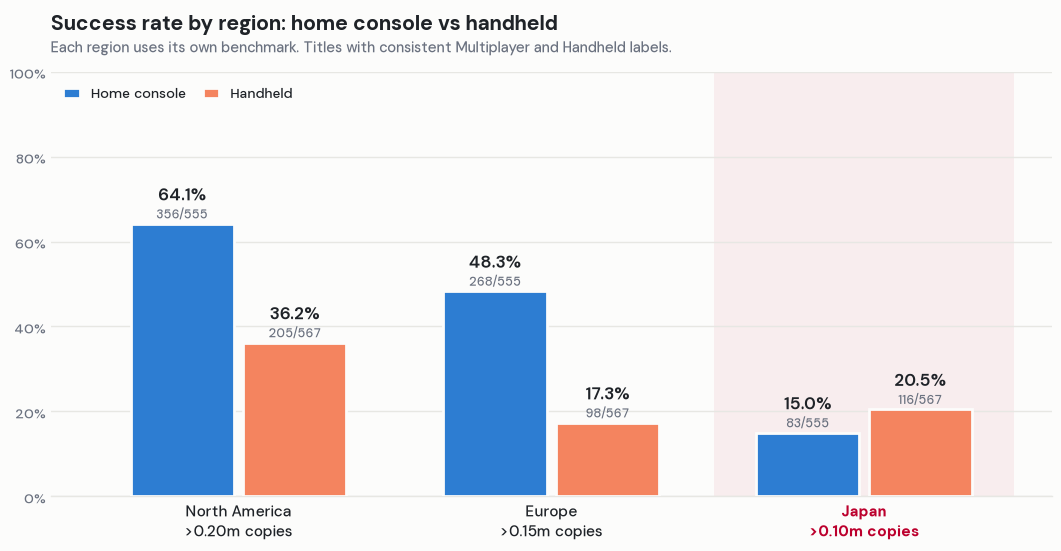

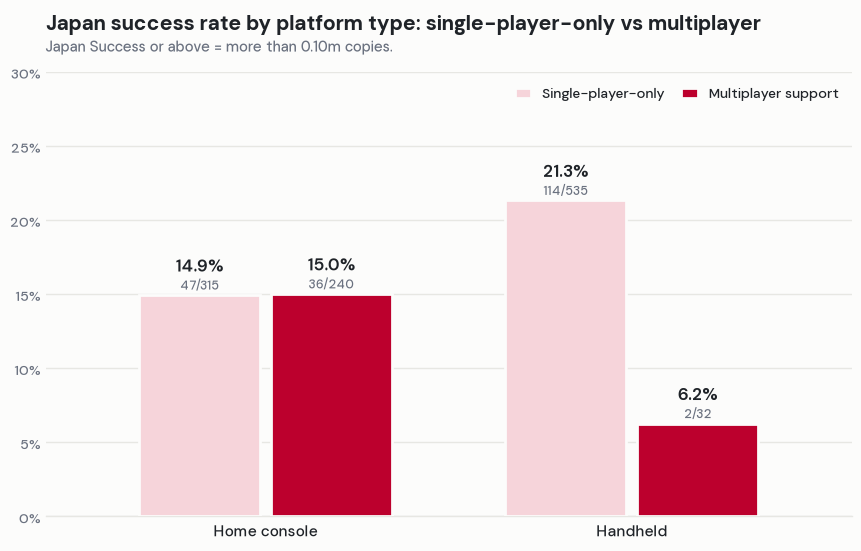

In [6]:
# Twist charts: platform type by region, then Japan sliced by platform type (lecture notes Section 2.3).
# Same sample for both: titles with consistent Multiplayer and Handheld labels.
both = titles[titles.Multiplayer.notna() & titles.Handheld.notna()]
PLATFORM = ["Home console", "Handheld"]
platform_rows = [row | {"slice": "All"} for region in regions
                 for row in summarise(both, "Consistent Multiplayer and Handheld", "Handheld", region)]
platform_rows += [row | {"slice": PLATFORM[hh]} for hh in [0, 1]
                  for row in summarise(both[both.Handheld == hh], "Consistent Multiplayer and Handheld",
                                       region="JapanSales")]
platform = pd.DataFrame(platform_rows)
save_table(platform, "mp_story_platform_twist.csv")

fig, ax = plt.subplots(figsize=(10.5, 5.4), layout="constrained")
groups = []
for label, region in zip(REGION_TICKS, regions[1:]):
    s = platform.query("slice == 'All' and region == @region").set_index("value")
    groups.append((label, [(s.success_pct[v], int(s.success_n[v]), int(s.n[v])) for v in [0, 1]]))
paired_bars(ax, groups, [HOME, HANDHELD], PLATFORM, legend="upper left")
japan_spotlight(ax, 2)
titled(ax, "Success rate by region: home console vs handheld",
       "Each region uses its own benchmark. Titles with consistent Multiplayer and Handheld labels.")
save_figure(fig, "mp_08_platform_by_region.png")

fig, ax = plt.subplots(figsize=(8.5, 5.4), layout="constrained")
groups = []
for name in PLATFORM:
    s = platform.query("slice == @name").set_index("value")
    groups.append((name, [(s.success_pct[v], int(s.success_n[v]), int(s.n[v])) for v in [0, 1]]))
# Japan flag colours: pale blush for single-player, solid red for multiplayer
paired_bars(ax, groups, [JAPAN_BLUSH, JAPAN_RED], NAMES, top=30)
titled(ax, "Japan success rate by platform type: single-player-only vs multiplayer",
       "Japan Success or above = more than 0.10m copies.")
save_figure(fig, "mp_09_japan_by_platform.png")

## Bridge chart — Do Japan's recorded zeros explain the reversal?
Left: share of titles with zero Japan sales in each group. Right: Japan success rate among titles with some recorded Japan sales. Uses the main comparison (titles whose versions agree on Multiplayer).

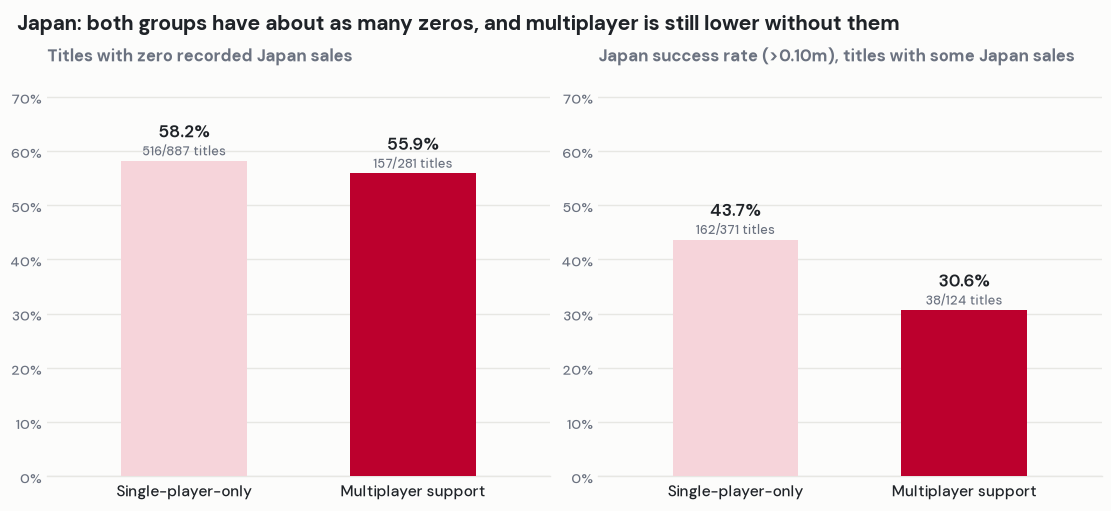

In [7]:
# Bridge chart: Japan's recorded zeros don't explain the reversal.
# Left = share of titles with 0 Japan sales, right = success rate once those 0s are set aside.
japan = outcomes.query("sample == 'All titles' and region == 'JapanSales'").set_index("value")
fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
for ax, heading in [(axes[0], "Titles with zero recorded Japan sales"),
                    (axes[1], "Japan success rate (>0.10m), titles with some Japan sales")]:
    for value in [0, 1]:
        row = japan.loc[value]
        zeros = int(row.n - row.positive_n)
        if ax is axes[0]:
            pct, detail = 100 * zeros / row.n, f"{zeros}/{int(row.n)} titles"
        else:
            pct, detail = 100 * row.success_n / row.positive_n, f"{int(row.success_n)}/{int(row.positive_n)} titles"
        ax.bar(value, pct, color=[JAPAN_BLUSH, JAPAN_RED][value], width=.55, zorder=3)
        bar_label(ax, value, pct, detail)
    ax.set_xticks([0, 1], NAMES)
    ax.set_xlim(-.6, 1.6)
    ax.set_ylim(0, 75)
    ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    ax.set_title(heading, loc="left", fontsize=12, fontweight="bold", color=MUTED)
fig.suptitle("Japan: both groups have about as many zeros, and multiplayer is still lower without them",
             x=.01, ha="left", fontsize=15, fontweight="bold")
save_figure(fig, "mp_10_japan_zeros.png")

## Follow-up chart — The multiplayer gap within each platform type
Gap = multiplayer minus single-player-only Success-or-above rate, in percentage points. "All titles" uses the main comparison; the platform slices use titles with consistent Multiplayer and Handheld labels.

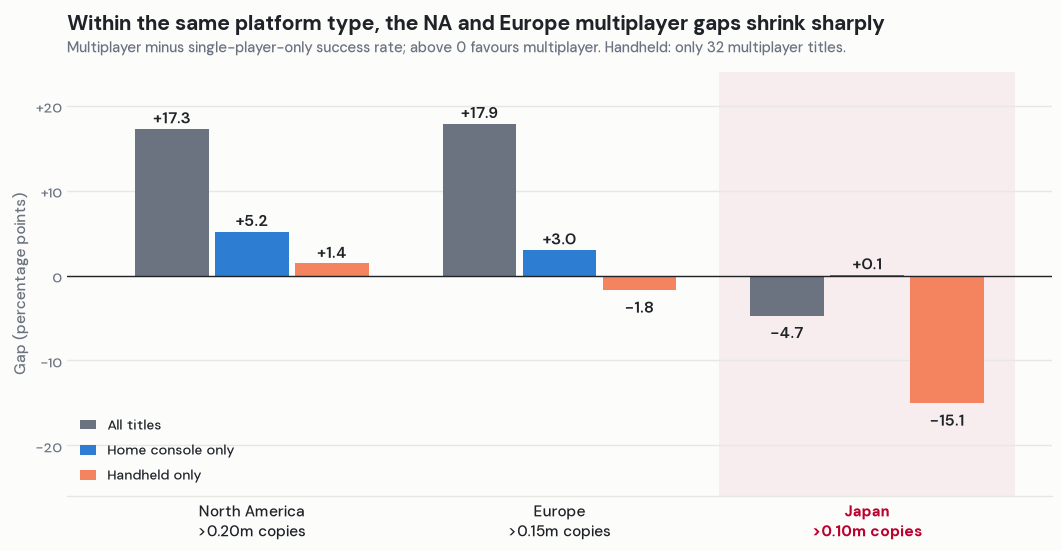

In [8]:
# NA/EU follow-up: the multiplayer gap overall vs within each platform type.
# Gap = multiplayer rate minus single-player-only rate, in percentage points.
gap_rows = []
for region in regions[1:]:
    s = outcomes.query("sample == 'All titles' and region == @region").set_index("value")
    gap_rows.append({"region": region, "slice": "All titles", "gap_pts": s.success_pct[1] - s.success_pct[0],
                     "mp_n": int(s.n[1]), "sp_n": int(s.n[0])})
    for hh in [0, 1]:
        s = pd.DataFrame(summarise(both[both.Handheld == hh], "Consistent Multiplayer and Handheld",
                                   region=region)).set_index("value")
        gap_rows.append({"region": region, "slice": PLATFORM[hh] + " only",
                         "gap_pts": s.success_pct[1] - s.success_pct[0], "mp_n": int(s.n[1]), "sp_n": int(s.n[0])})
gaps = pd.DataFrame(gap_rows)
save_table(gaps, "mp_story_platform_gaps.csv")

fig, ax = plt.subplots(figsize=(10.5, 5.4), layout="constrained")
slices = ["All titles", "Home console only", "Handheld only"]
for i, (name, color) in enumerate(zip(slices, [MUTED, HOME, HANDHELD])):
    d = gaps[gaps.slice == name].reset_index()
    xs = np.arange(3) + (i - 1) * .26
    ax.bar(xs, d.gap_pts, width=.24, color=color, zorder=3, label=name)
    for x, v in zip(xs, d.gap_pts):
        ax.annotate(f"{v:+.1f}", (x, v), xytext=(0, 4 if v >= 0 else -16), textcoords="offset points",
                    ha="center", fontsize=11.5, fontweight="semibold", color=INK)
ax.axhline(0, color=INK, linewidth=1, zorder=4)
ax.set_xticks(range(3), REGION_TICKS)
ax.set_xlim(-.6, 2.6)
ax.set_ylim(-26, 24)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:+.0f}" if v else "0")
ax.set_ylabel("Gap (percentage points)")
ax.legend(loc="lower left", ncol=1, handlelength=1.2)
japan_spotlight(ax, 2)
titled(ax, "Within the same platform type, the NA and Europe multiplayer gaps shrink sharply",
       "Multiplayer minus single-player-only success rate; above 0 favours multiplayer. Handheld: only 32 multiplayer titles.")
save_figure(fig, "mp_11_gap_by_platform.png")

## Export supporting tables and record hashes
Save the additional evidence tables and the source/output hash manifest. Confirm that the source CSV stayed unchanged during execution.

In [9]:
# Small overview of deliberately different candidate factors, not a correlation ranking.
screen_features = ["Multiplayer", "Online", "Handheld", "Licensed", "Genre: Strategy"]
screen = pd.DataFrame([row for feature in screen_features
                       for row in summarise(titles, "All titles", feature=feature)])
save_table(screen, "mp_story_candidate_screen.csv")

contexts = []
for f in ["Genre: Action", "Genre: Sports", "Genre: Strategy", "Genre: Role-Playing (RPG)"]:
    contexts.extend(summarise(titles[titles[f] == 1], f))
for suffix in ["Any", "All"]:
    contexts.extend(summarise(titles, suffix + "-version rule", feature="Multiplayer" + suffix))
mixed = titles[titles.Multiplayer.isna()]
contexts.append({"sample": "Discordant versions", "feature": "Multiplayer", "value": np.nan,
                 "n": len(mixed), "success_n": int(mixed.GlobalSalesSuccess.sum()),
                 "success_pct": 100 * mixed.GlobalSalesSuccess.mean()})
save_table(pd.DataFrame(contexts), "mp_story_context_checks.csv")

source_after = hashlib.sha256(SOURCE.read_bytes()).hexdigest()
if source_before != source_after:
    raise RuntimeError("The source CSV changed during the chart run")
manifest = {"source_sha256": source_after, "source_rows": len(raw), "title_n": len(titles),
            "common_multiplayer_n": int(titles.Multiplayer.notna().sum()),
            "discordant_multiplayer_n": int(titles.Multiplayer.isna().sum()),
            "outputs": {str(p.relative_to(HERE)): hashlib.sha256(p.read_bytes()).hexdigest() for p in paths}}
(HERE / "multiplayer_story_manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")

1751